In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = '/content/CLEANED_DATASET (1) (1).csv'
df = pd.read_csv(file_path)

# Display the first 5 rows of the DataFrame
print('First 5 rows of the dataset:')
display(df.head())

# Display information about the DataFrame, including data types and non-null valuesu
print('\nDataFrame Info:')
df.info()

First 5 rows of the dataset:


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_12_Pat,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_16_Milk,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_20_But,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_2_Bev,27.5,9.0,247.5,Credit Card,Online,2022-05-07,False
4,TXN_4575373,CUST_05,Food,Item_14_Food,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  object 
 1   Customer ID       12575 non-null  object 
 2   Category          12575 non-null  object 
 3   Item              12575 non-null  object 
 4   Price Per Unit    12575 non-null  float64
 5   Quantity          12575 non-null  float64
 6   Total Spent       12575 non-null  float64
 7   Payment Method    12575 non-null  object 
 8   Location          12575 non-null  object 
 9   Transaction Date  12575 non-null  object 
 10  Discount Applied  12575 non-null  bool   
dtypes: bool(1), float64(3), object(7)
memory usage: 994.8+ KB


Descriptive Statistics for Numerical Columns:


,Price Per Unit,Quantity,Total Spent
count,12575.000000,12575.000000,12575.000000
mean,23.370736,5.558648,128.652485
std,10.651130,2.790160,92.554204
min,5.000000,1.000000,5.000000
25%,14.000000,3.000000,55.000000
50%,23.000000,6.000000,108.500000
75%,32.000000,8.000000,184.000000
max,41.000000,10.000000,410.000000


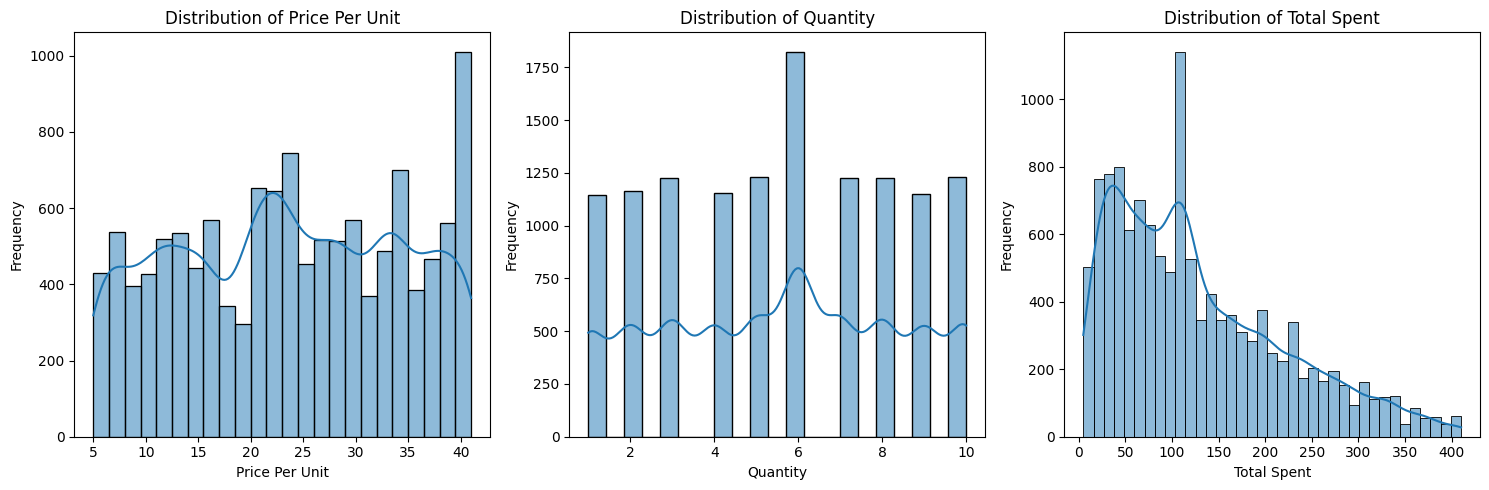

In [ ]:
# Univariate Analysis for Numerical Columns
numerical_cols = ['Price Per Unit', 'Quantity', 'Total Spent']

print('Descriptive Statistics for Numerical Columns:')
display(df[numerical_cols].describe())

# Plotting Histograms for Numerical Columns
plt.figure(figsize=(15, 5))
for i, col in enumerate(numerical_cols):
    plt.subplot(1, len(numerical_cols), i + 1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


Value Counts for Category:


,count
Category,
Electric Household Essentials,1591
Furniture,1591
Food,1588
Milk Products,1584
Butchers,1568
Beverages,1567
Computers And Electric Accessories,1558
Patisserie,1528



Value Counts for Payment Method:


,count
Payment Method,
Cash,4310
Digital Wallet,4144
Credit Card,4121



Value Counts for Location:


,count
Location,
Online,6354
In-Store,6221


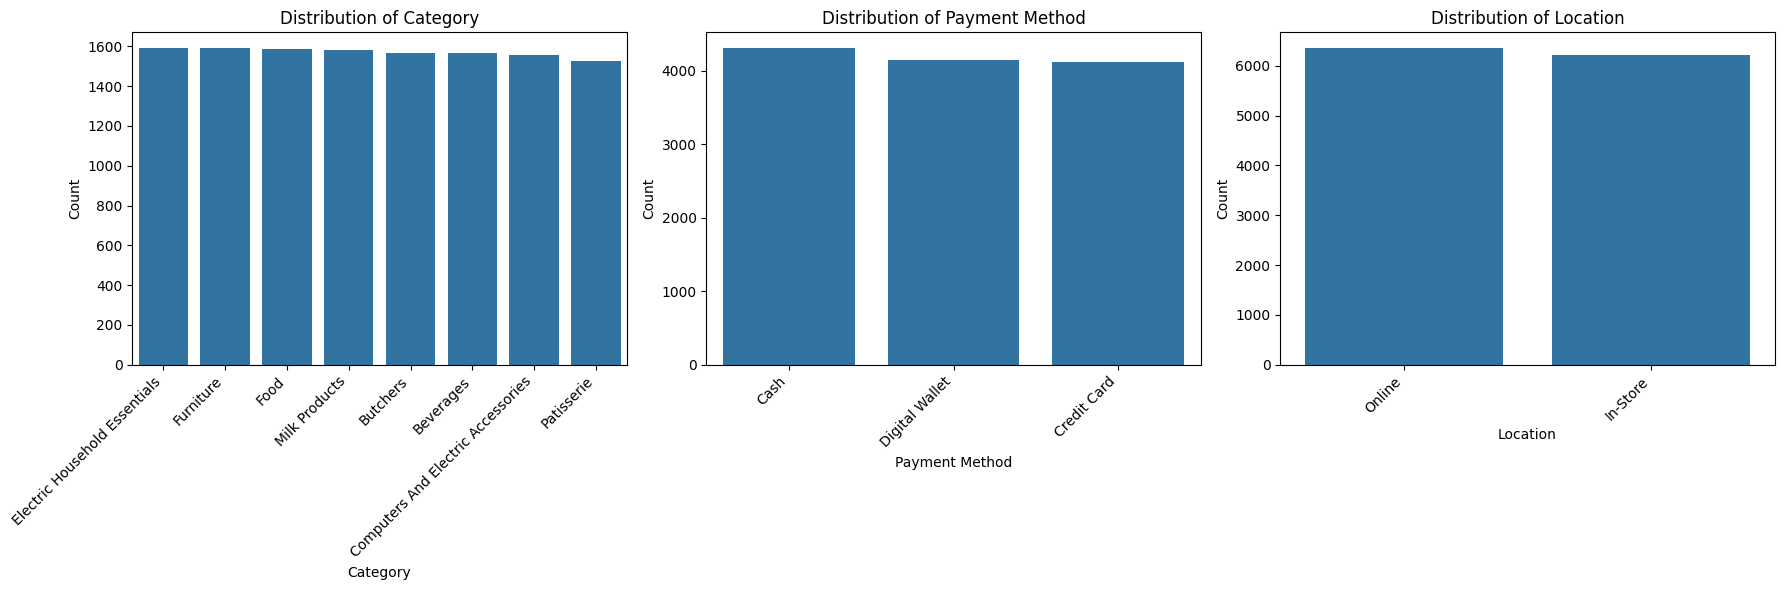

In [ ]:
# Univariate Analysis for Categorical Columns
categorical_cols = ['Category', 'Payment Method', 'Location']

for col in categorical_cols:
    print(f'\nValue Counts for {col}:')
    display(df[col].value_counts())

# Plotting Bar Plots for Categorical Columns
plt.figure(figsize=(18, 6))
for i, col in enumerate(categorical_cols):
    plt.subplot(1, len(categorical_cols), i + 1)
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Average Total Spent per Category:


,Total Spent
Category,
Butchers,137.725765
Electric Household Essentials,133.231301
Beverages,130.683472
Food,128.232683
Computers And Electric Accessories,128.053273
Furniture,127.271527
Patisserie,125.409686
Milk Products,118.588068


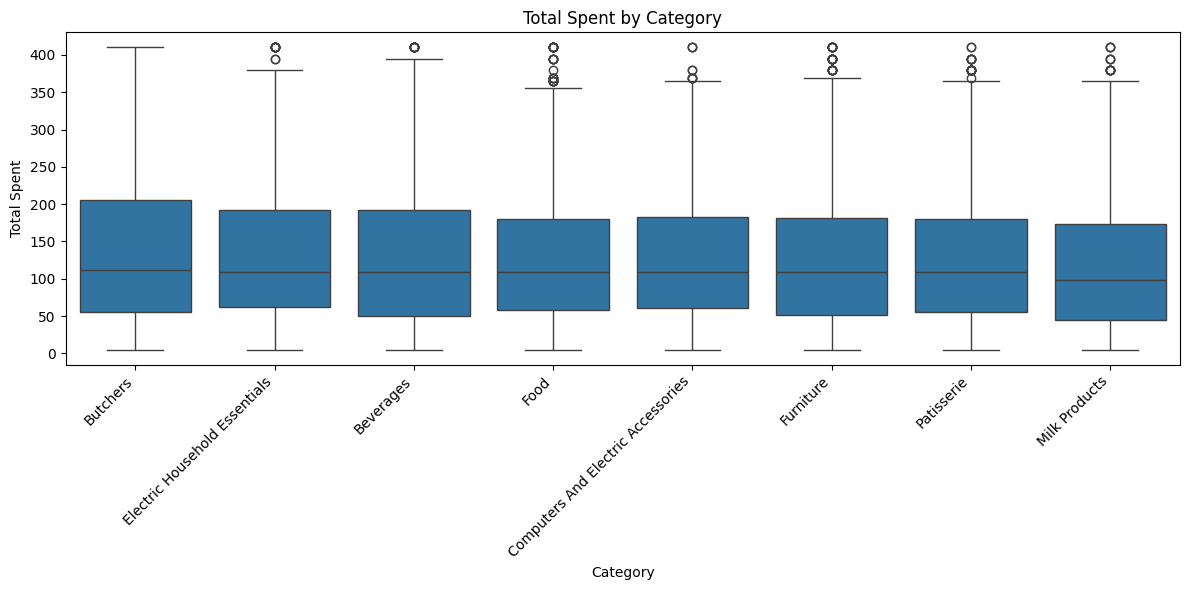

In [ ]:
# Bivariate Analysis - Category vs. Total Spent

# Calculate average total spent per category
avg_spent_per_category = df.groupby('Category')['Total Spent'].mean().sort_values(ascending=False)
print('Average Total Spent per Category:')
display(avg_spent_per_category)

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Category', y='Total Spent', order=avg_spent_per_category.index)
plt.title('Total Spent by Category')
plt.xlabel('Category')
plt.ylabel('Total Spent')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Average Total Spent per Payment Method:


,Total Spent
Payment Method,
Cash,129.986427
Credit Card,128.172288
Digital Wallet,127.742640


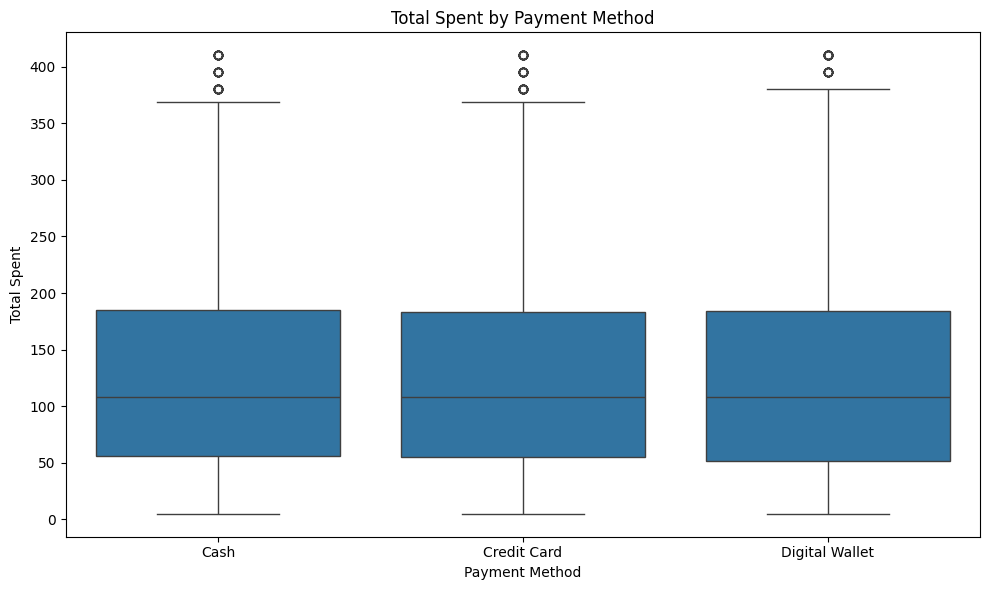

In [ ]:
# Bivariate Analysis - Payment Method vs. Total Spent

# Calculate average total spent per payment method
avg_spent_by_payment_method = df.groupby('Payment Method')['Total Spent'].mean().sort_values(ascending=False)
print('Average Total Spent per Payment Method:')
display(avg_spent_by_payment_method)

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Payment Method', y='Total Spent', order=avg_spent_by_payment_method.index)
plt.title('Total Spent by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Spent')
plt.tight_layout()
plt.show()

Average Total Spent per Location:


,Total Spent
Location,
Online,129.449795
In-Store,127.838129


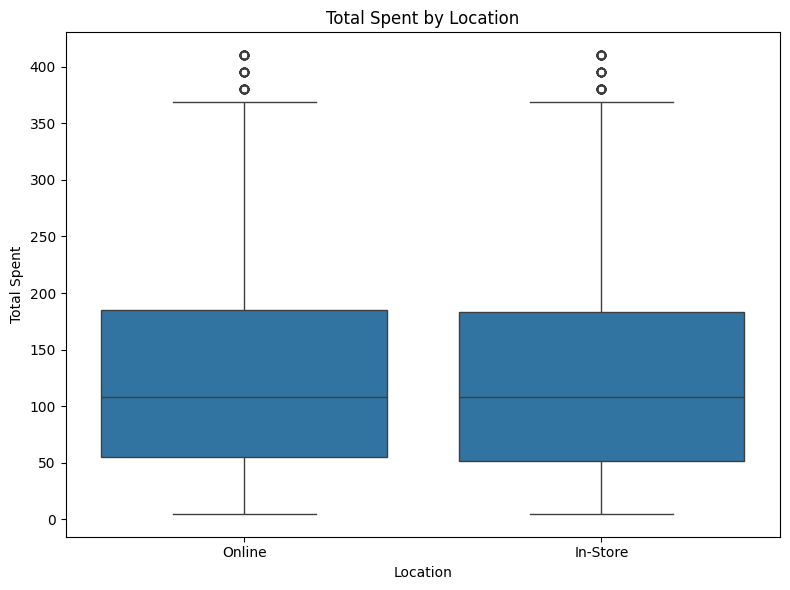

In [ ]:
# Bivariate Analysis - Location vs. Total Spent

# Calculate average total spent per location
avg_spent_by_location = df.groupby('Location')['Total Spent'].mean().sort_values(ascending=False)
print('Average Total Spent per Location:')
display(avg_spent_by_location)

plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Location', y='Total Spent', order=avg_spent_by_location.index)
plt.title('Total Spent by Location')
plt.xlabel('Location')
plt.ylabel('Total Spent')
plt.tight_layout()
plt.show()

### Feature Engineering
We will now prepare our variables for machine learning models:
1. Check and correct the skewness of numerical features (such as `Total Spent` or `Price Per Unit`).
2. Encode categorical features (`Category`, `Payment Method`, `Location`, `Discount Applied`).
3. Scale the numerical columns.

In [4]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Load the dataset if it is not already loaded
try:
    df
except NameError:
    file_path = '/content/CLEANED_DATASET (1) (1).csv'
    df = pd.read_csv(file_path)

# Create a copy of the dataframe to keep the original raw data intact
fe_df = df.copy()

# 1. Parse 'Transaction Date' as datetime to extract temporal features
fe_df['Transaction Date'] = pd.to_datetime(fe_df['Transaction Date'])
fe_df['Transaction Year'] = fe_df['Transaction Date'].dt.year
fe_df['Transaction Month'] = fe_df['Transaction Date'].dt.month
fe_df['Transaction Day'] = fe_df['Transaction Date'].dt.day
fe_df['Transaction DayOfWeek'] = fe_df['Transaction Date'].dt.dayofweek

# Drop raw IDs and raw transaction date
fe_df = fe_df.drop(columns=['Transaction ID', 'Customer ID', 'Transaction Date'])

# 2. Fix skewness of highly skewed numerical columns using Log Transform (1 + x)
numerical_cols = ['Price Per Unit', 'Quantity', 'Total Spent']
for col in numerical_cols:
    skewness = fe_df[col].skew()
    print(f'Skewness of {col}: {skewness:.4f}')
    if abs(skewness) > 0.75:
        print(f'-> Applying log1p transformation to reduce skewness in {col}.')
        fe_df[f'{col}_log'] = np.log1p(fe_df[col])
        # Replace original with the log transformed column for subsequent scaling
        fe_df = fe_df.drop(columns=[col])

# Update our lists of features to process
numeric_features = [col + '_log' if f'{col}_log' in fe_df.columns else col for col in numerical_cols] + \
                   ['Transaction Year', 'Transaction Month', 'Transaction Day', 'Transaction DayOfWeek']
categorical_features = ['Category', 'Payment Method', 'Location', 'Discount Applied']

print('\nFeatures to be scaled:', numeric_features)
print('Features to be One-Hot encoded:', categorical_features)

Skewness of Price Per Unit: -0.0344
Skewness of Quantity: -0.0359
Skewness of Total Spent: 0.8809
-> Applying log1p transformation to reduce skewness in Total Spent.

Features to be scaled: ['Price Per Unit', 'Quantity', 'Total Spent_log', 'Transaction Year', 'Transaction Month', 'Transaction Day', 'Transaction DayOfWeek']
Features to be One-Hot encoded: ['Category', 'Payment Method', 'Location', 'Discount Applied']


In [5]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Ensure features list are defined in case of a kernel reset
try:
    numeric_features
    categorical_features
    fe_df
except NameError:
    # Fallback definitions based on the dataset structure
    numeric_features = ['Price Per Unit', 'Quantity', 'Total Spent_log', 'Transaction Year', 'Transaction Month', 'Transaction Day', 'Transaction DayOfWeek']
    categorical_features = ['Category', 'Payment Method', 'Location', 'Discount Applied']

# 3. Pipeline for scaling and encoding using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
    ])

# Fit and transform the processed dataset
processed_array = preprocessor.fit_transform(fe_df)

# Get feature names after transformation
encoded_cat_cols = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
feature_names = numeric_features + list(encoded_cat_cols)

# Recreate clean, engineered DataFrame
engineered_df = pd.DataFrame(processed_array, columns=feature_names)

print('Shape of the engineered dataset:', engineered_df.shape)
display(engineered_df.head())

Shape of the engineered dataset: (12575, 18)


,Price Per Unit,Quantity,Total Spent_log,Transaction Year,Transaction Month,Transaction Day,Transaction DayOfWeek,Category_Butchers,Category_Computers And Electric Accessories,Category_Electric Household Essentials,Category_Food,Category_Furniture,Category_Milk Products,Category_Patisserie,Payment Method_Credit Card,Payment Method_Digital Wallet,Location_Online,Discount Applied_True
0,-0.457316,1.591854,0.775412,1.119300,-0.675544,-0.867107,-1.504835,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0
1,0.528534,1.233438,1.172797,-0.049542,0.180861,0.836889,1.497514,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0
2,-0.175644,-1.275479,-0.896675,-1.218385,1.037265,-1.207907,-0.504052,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,0.387699,1.233438,1.111435,-1.218385,-0.390076,-0.980707,0.997122,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,-1.020659,0.516605,-0.086110,-1.218385,1.037265,-1.548706,1.497514,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
